# A geometric solution for ordinal relations
The previous notebook showed that the query-key matrix $M = W_k^\top W_q$ must be antisymmetric to represent an order. Here we build an explicit solution with a 2-dimensional head and show what it looks like.

## Preliminaries
Writing a vector in $\mathbb{R}^2$ in polar coordinates, $(r, \theta) = (r\cos\theta, r\sin\theta)$, the dot product of two vectors becomes
$$
(r_1,\theta_1)\cdot (r_2,\theta_2)=r_1 r_2 (\cos \theta_1 \cos \theta_2 + \sin \theta_1 \sin \theta_2) = r_1 r_2 \cos(\theta_1 - \theta_2).
$$

## The construction
1. **Keys on an arc.** Give item $i$ a unit key $k_i$ at angle $\theta_i$, with the angles decreasing with rank ($A$ highest) and all keys inside a quarter circle.
2. **Queries are rotated keys.** Set each query to its key rotated by $90^\circ$: $q_i = R_{90^\circ} k_i$, at angle $\theta_i + \pi/2$.

Then the score for the pair (first item $i$, second item $j$) is
$$
q_j \cdot k_i = \cos\!\left(\theta_j + \tfrac{\pi}{2} - \theta_i\right) = \sin(\theta_i - \theta_j),
$$
which is positive exactly when $\theta_i > \theta_j$, i.e. when $i$ comes before $j$. Because all angles lie within a half circle, the sign is correct for **every** pair, adjacent or not. In matrix form $M = K^\top R_{90^\circ} K$, and since $R_{90^\circ}$ is antisymmetric, so is $M$: this is the antisymmetric structure from the previous notebook in its simplest form.

Geometrically, each key's null space (the line perpendicular to it) splits the queries: items ranked below fall on one side, items ranked above on the other.

## Imports

In [1]:
import numpy as np
import string
import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import seaborn as sns

from relational_attention.tasks import OrdinalRelationsDataset
from relational_attention.models import QueryKeyScorer
from relational_attention.training import train_model, evaluate_model

## Define vectors

In [2]:
num_stimuli = 5
angle_increase = np.pi / 8

In [3]:
# Item 0 (A) gets the largest angle, item 4 (E) gets angle 0
angles = np.array([(num_stimuli - 1 - i) * angle_increase for i in range(num_stimuli)])
keys = np.stack([np.cos(angles), np.sin(angles)])      # (2, num_stimuli)
queries = np.stack([-keys[1], keys[0]])                # rotate each key by 90 degrees
np.degrees(angles)

array([90. , 67.5, 45. , 22.5,  0. ])

## Plot vectors

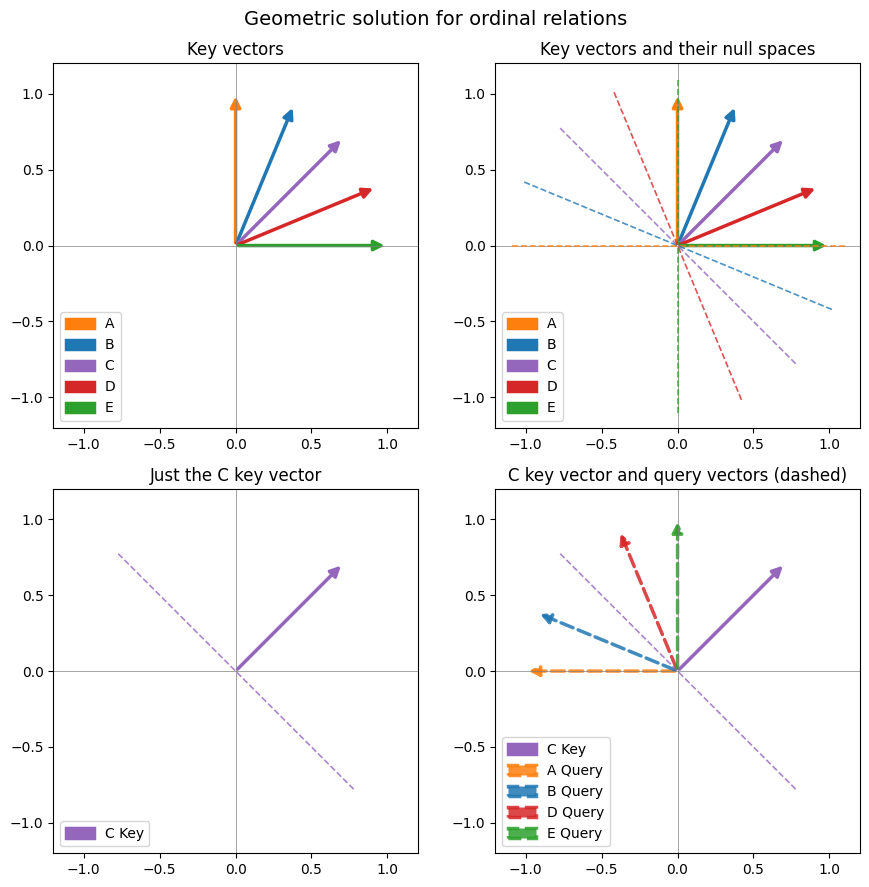

In [4]:
colors = ['tab:orange', 'tab:blue', 'tab:purple', 'tab:red', 'tab:green']
letters = list(string.ascii_uppercase[:num_stimuli])
c_idx = 2


def setup(ax, title):
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-1.2, 1.2)
    ax.set_aspect('equal')
    ax.set_title(title)


def arrow(ax, vec, color, label, dashed=False):
    ax.add_patch(FancyArrowPatch((0, 0), tuple(vec), arrowstyle='-|>', mutation_scale=15, linewidth=2.5,
                                 linestyle='--' if dashed else '-', color=color, alpha=0.85 if dashed else 1,
                                 label=label))


def null_space(ax, vec, color):
    n = np.array([-vec[1], vec[0]]) * 1.1
    ax.plot([-n[0], n[0]], [-n[1], n[1]], linestyle='--', color=color, linewidth=1.2, alpha=0.8)


fig, axes = plt.subplots(2, 2, figsize=(9, 9))

setup(axes[0, 0], 'Key vectors')
for i in range(num_stimuli):
    arrow(axes[0, 0], keys[:, i], colors[i], letters[i])

setup(axes[0, 1], 'Key vectors and their null spaces')
for i in range(num_stimuli):
    arrow(axes[0, 1], keys[:, i], colors[i], letters[i])
    null_space(axes[0, 1], keys[:, i], colors[i])

setup(axes[1, 0], f'Just the {letters[c_idx]} key vector')
arrow(axes[1, 0], keys[:, c_idx], colors[c_idx], f'{letters[c_idx]} Key')
null_space(axes[1, 0], keys[:, c_idx], colors[c_idx])

setup(axes[1, 1], f'{letters[c_idx]} key vector and query vectors (dashed)')
arrow(axes[1, 1], keys[:, c_idx], colors[c_idx], f'{letters[c_idx]} Key')
null_space(axes[1, 1], keys[:, c_idx], colors[c_idx])
for i in range(num_stimuli):
    if i != c_idx:
        arrow(axes[1, 1], queries[:, i], colors[i], f'{letters[i]} Query', dashed=True)

for ax in axes.flat:
    ax.legend(loc='lower left')

plt.suptitle('Geometric solution for ordinal relations', fontsize=14)
plt.tight_layout()
plt.savefig('../results/geometric_solution.png', dpi=150)
plt.show()

Queries for items ranked below $C$ ($D$, $E$) land on the positive side of $C$'s null space and queries for items ranked above ($A$, $B$) land on the negative side, which is exactly the sign pattern needed.

## Check: the construction solves the task
Load the constructed vectors into a `QueryKeyScorer` and evaluate it on every pair.

In [5]:
model = QueryKeyScorer(embed_dim=num_stimuli, head_dim=2)
with torch.no_grad():
    model.W_k.weight.copy_(torch.tensor(keys, dtype=torch.float32))
    model.W_q.weight.copy_(torch.tensor(queries, dtype=torch.float32))

test = OrdinalRelationsDataset(num_samples=1000, num_items=num_stimuli, pairs='all')
print('Accuracy on all pairs:', evaluate_model(model, DataLoader(test, batch_size=64)))

Accuracy on all pairs: 1.0


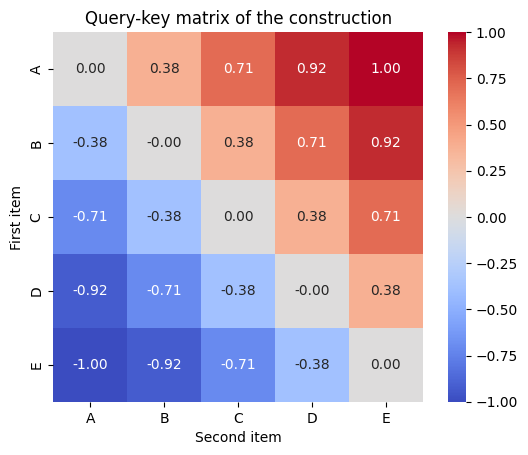

Antisymmetric: True


In [6]:
M = model.query_key_matrix().detach()
sns.heatmap(M, cmap='coolwarm', center=0, annot=True, fmt='.2f', xticklabels=letters, yticklabels=letters, square=True)
plt.xlabel('Second item')
plt.ylabel('First item')
plt.title('Query-key matrix of the construction')
plt.show()
print('Antisymmetric:', torch.allclose(M, -M.T, atol=1e-6))

## Comparison: a trained 2-dimensional head
For comparison, train a `QueryKeyScorer` with a 2-dimensional head on all pairs of 10 items and plot its learned key and query vectors (the columns of $W_k$ and $W_q$).

In [7]:
torch.manual_seed(42)
num_items = 10
dataset = OrdinalRelationsDataset(num_samples=1000, num_items=num_items, pairs='all')
loader = DataLoader(dataset, batch_size=16, shuffle=True)

trained = QueryKeyScorer(embed_dim=num_items, head_dim=2)
optimizer = torch.optim.Adam(trained.parameters(), lr=1e-3)
loss = train_model(trained, loader, optimizer=optimizer, epochs=500, verbose=False)
print(f'final loss {loss[-1]:.4f}   accuracy {evaluate_model(trained, loader):.3f}')

final loss 0.0000   accuracy 1.000


In [8]:
K = trained.W_k.weight.detach().numpy()
Q = trained.W_q.weight.detach().numpy()

key_angles = np.degrees(np.arctan2(K[1], K[0]))
rotation = (np.degrees(np.arctan2(Q[1], Q[0])) - key_angles + 180) % 360 - 180
for letter, a, r in zip(string.ascii_uppercase, key_angles, rotation):
    print(f'{letter}: key angle {a:7.1f}   query - key angle {r:7.1f}')

A: key angle    80.0   query - key angle   -91.9
B: key angle    92.9   query - key angle   -89.7
C: key angle   110.8   query - key angle   -90.0
D: key angle   133.8   query - key angle   -91.1
E: key angle   153.6   query - key angle   -87.9
F: key angle   171.4   query - key angle   -92.5
G: key angle  -175.4   query - key angle   -88.9
H: key angle  -158.7   query - key angle   -89.7
I: key angle  -136.9   query - key angle   -91.3
J: key angle  -117.3   query - key angle   -88.8


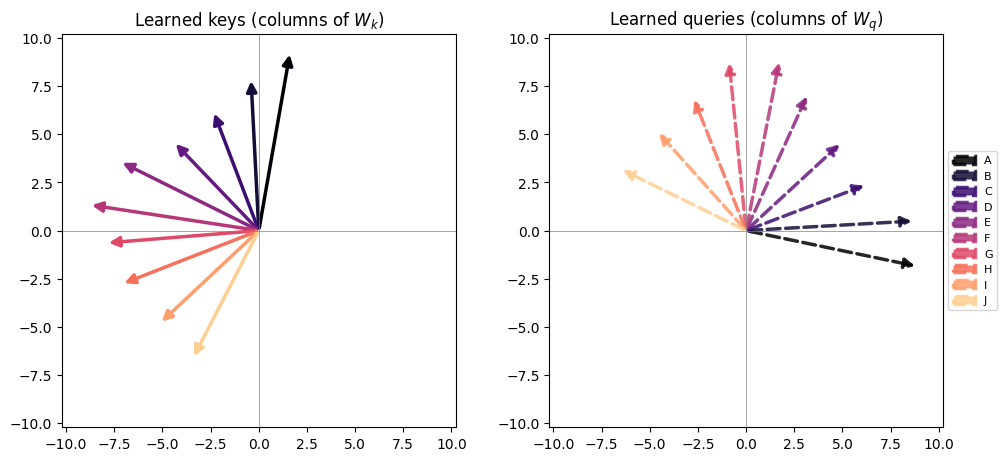

In [9]:
cmap = plt.cm.magma
lim = 1.1 * max(np.abs(Q).max(), np.abs(K).max())

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
for ax, (W, title, dashed) in zip(axes, [(K, 'Learned keys (columns of $W_k$)', False),
                                         (Q, 'Learned queries (columns of $W_q$)', True)]):
    ax.axhline(0, color='gray', linewidth=0.5)
    ax.axvline(0, color='gray', linewidth=0.5)
    for i in range(num_items):
        arrow(ax, W[:, i], cmap(i / num_items), string.ascii_uppercase[i], dashed=dashed)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_title(title)
axes[1].legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8)
plt.savefig('../results/learned_solution.png', dpi=150, bbox_inches='tight')
plt.show()

The trained head recovers the construction up to a reflection: the keys are fanned out in rank order across less than a half circle, and every query is its own key rotated by about $90^\circ$ (here $-90^\circ$, because the keys rotate counter-clockwise with rank instead of clockwise).

## Is this what training finds in general?
Repeat the training from 10 random initializations. For each run we record the accuracy, the span of the key angles, and the largest deviation of any query-key rotation from $\pm 90^\circ$.

In [10]:
rows = []
for seed in range(10):
    torch.manual_seed(seed)
    run = QueryKeyScorer(embed_dim=num_items, head_dim=2)
    optimizer = torch.optim.Adam(run.parameters(), lr=1e-3)
    train_model(run, loader, optimizer=optimizer, epochs=500, verbose=False)

    K = run.W_k.weight.detach().numpy()
    Q = run.W_q.weight.detach().numpy()
    key_angles = np.unwrap(np.arctan2(K[1], K[0]))
    rotation = (np.degrees(np.arctan2(Q[1], Q[0]) - np.arctan2(K[1], K[0])) + 180) % 360 - 180
    rows.append({
        'seed': seed,
        'accuracy': evaluate_model(run, loader),
        'key span (deg)': float(np.degrees(key_angles.max() - key_angles.min())),
        'keys in rank order': bool(np.all(np.diff(key_angles) > 0) or np.all(np.diff(key_angles) < 0)),
        'max |rotation| - 90 (deg)': float(np.max(np.abs(np.abs(rotation) - 90))),
    })

import pandas as pd
pd.DataFrame(rows).round(2)

,seed,accuracy,key span (deg),keys in rank order,max |rotation| - 90 (deg)
0,0,1.0,165.89,True,2.02
1,1,1.0,161.87,True,3.16
2,2,1.0,165.62,True,2.87
3,3,1.0,162.12,True,2.56
4,4,1.0,163.34,True,1.69
5,5,1.0,163.58,True,1.81
6,6,1.0,166.39,True,3.94
7,7,1.0,165.16,True,1.55
8,8,1.0,164.56,True,1.60
9,9,1.0,166.03,True,1.64
